# Chapter 4: Sector ETF vs DIY Basket

*Should you buy the sector ETF, or build the sector exposure yourself?*

For each sector, this chapter compares the sector's **SPDR ETF** (e.g. XLK for Technology) with a **DIY basket** of the sector's stocks, built with simple, transparent rules. The question is whether the ETF gives an exposure similar to the basket, and how their growth and risk evolve over time.

- **Inputs:** `data_processed/stocks_sect.parquet` (stocks, sectors, dollar volume) and `data_processed/etfs_clean.parquet` (sector ETFs).
- **Output:** the 22 Chapter 4 figures of the website (performance and volatility for each of the 11 sectors) in `website/figures/chapter4/`.

The per-sector interpretations shown next to the charts on the website are written by hand in `website/content/chapter4_writeups.json`.

**Contents**
1. Setup
2. The DIY basket rule
3. ETF vs basket, sector by sector

## 1. Setup

In [1]:
from pathlib import Path

import pandas as pd

from src.chapters.chapter4 import SECTOR_ETFS, basket_returns, etf_returns, plot_performance, plot_volatility
from src.utils.figures import site_figure

PROCESSED_DIR = Path("data_processed")
FIG_SECTION = "chapter4"

END_DATE = "2020-04-01"  # last date of the price data
WEIGHT_CAP = 0.10        # no stock above 10% of the basket
WEIGHT_LAG = 1           # weights use yesterday's dollar volume
VOL_WINDOW = 60          # days for the rolling volatility


def slug(sector):
    return sector.lower().replace(" ", "_")

## 2. The DIY basket rule

For each sector and day *t*:

1. **Universe:** the sector's stocks that have a return on day *t*.
2. **Weights:** each stock's **dollar volume** (`Close × Volume`) on day *t − 1*. Using yesterday's value avoids look-ahead: today's volume is only known at the close.
3. **Cap:** no stock above **10%**; the excess is spread over the other stocks (repeated until no weight is above the cap). On days with fewer than 10 stocks, the basket is equally weighted.
4. **Basket return:** the sum of weight × daily return of each stock.

The ETF's daily return comes from its `Adj Close`, so it includes dividends like the stocks' returns. Both series are compared on the same days, from the ETF's first day to 2020-04-01.

In [2]:
stocks = pd.read_parquet(PROCESSED_DIR / "stocks_sect.parquet", columns=["Date", "Symbol", "Sector", "Return", "DollarVolume"])
etfs = pd.read_parquet(PROCESSED_DIR / "etfs_clean.parquet", columns=["Date", "Symbol", "Adj Close"])

pairs, summary = {}, []
for sector, etf in SECTOR_ETFS.items():
    r_etf = etf_returns(etfs, etf)
    if r_etf.empty:
        summary.append({"sector": sector, "ETF": etf, "note": "ETF not in the data"})
        continue
    dates = r_etf.loc[:END_DATE].index
    basket, weights = basket_returns(stocks, sector, dates, cap=WEIGHT_CAP, lag=WEIGHT_LAG)
    pair = pd.concat([r_etf, basket], axis=1).dropna()
    pairs[sector] = pair
    summary.append({
        "sector": sector, "ETF": etf,
        "first day": pair.index.min().date(), "days": len(pair),
        "stocks in the basket (median per day)": int(weights.notna().sum(axis=1).loc[pair.index].median()),
    })

pd.DataFrame(summary).set_index("sector")

,ETF,first day,days,stocks in the basket (median per day)
sector,,,,
Basic Materials,XLB,1998-12-23,5352,110
Communication Services,XLC,2018-06-20,449,116
Consumer Cyclical,XLY,1998-12-23,5352,194
Consumer Defensive,XLP,1998-12-23,5352,86
Energy,XLE,1998-12-23,5352,89
Financial Services,XLF,1998-12-23,5352,556
Healthcare,XLV,1998-12-23,5352,188
Industrials,XLI,1998-12-23,5352,276
Real Estate,XLRE,2015-10-09,1127,159


## 3. ETF vs basket, sector by sector

Two figures per sector:

- **Performance:** ETF and basket both rebased to 100 on their first common day, so the chart compares growth paths, not prices.
- **Volatility:** rolling 60-day volatility of both, annualised (× √252).

If the lines track closely, the ETF and the basket give a similar exposure. If they drift apart, they hold different stocks or weight them differently (the ETF uses market-cap weights with its own caps).

Saved website/figures/chapter4/performance_basic_materials.png
Saved website/figures/chapter4/volatility_basic_materials.png
Saved website/figures/chapter4/performance_communication_services.png
Saved website/figures/chapter4/volatility_communication_services.png
Saved website/figures/chapter4/performance_consumer_cyclical.png
Saved website/figures/chapter4/volatility_consumer_cyclical.png
Saved website/figures/chapter4/performance_consumer_defensive.png
Saved website/figures/chapter4/volatility_consumer_defensive.png
Saved website/figures/chapter4/performance_energy.png
Saved website/figures/chapter4/volatility_energy.png
Saved website/figures/chapter4/performance_financial_services.png
Saved website/figures/chapter4/volatility_financial_services.png
Saved website/figures/chapter4/performance_healthcare.png
Saved website/figures/chapter4/volatility_healthcare.png
Saved website/figures/chapter4/performance_industrials.png
Saved website/figures/chapter4/volatility_industrials.png
Saved 

/Users/chedliabdennebi/Desktop/cross-exchange-asset-analysis/src/chapters/chapter4.py:82: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(13, 5.2))
/Users/chedliabdennebi/Desktop/cross-exchange-asset-analysis/src/chapters/chapter4.py:82: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(13, 5.2))


Saved website/figures/chapter4/performance_utilities.png
Saved website/figures/chapter4/volatility_utilities.png


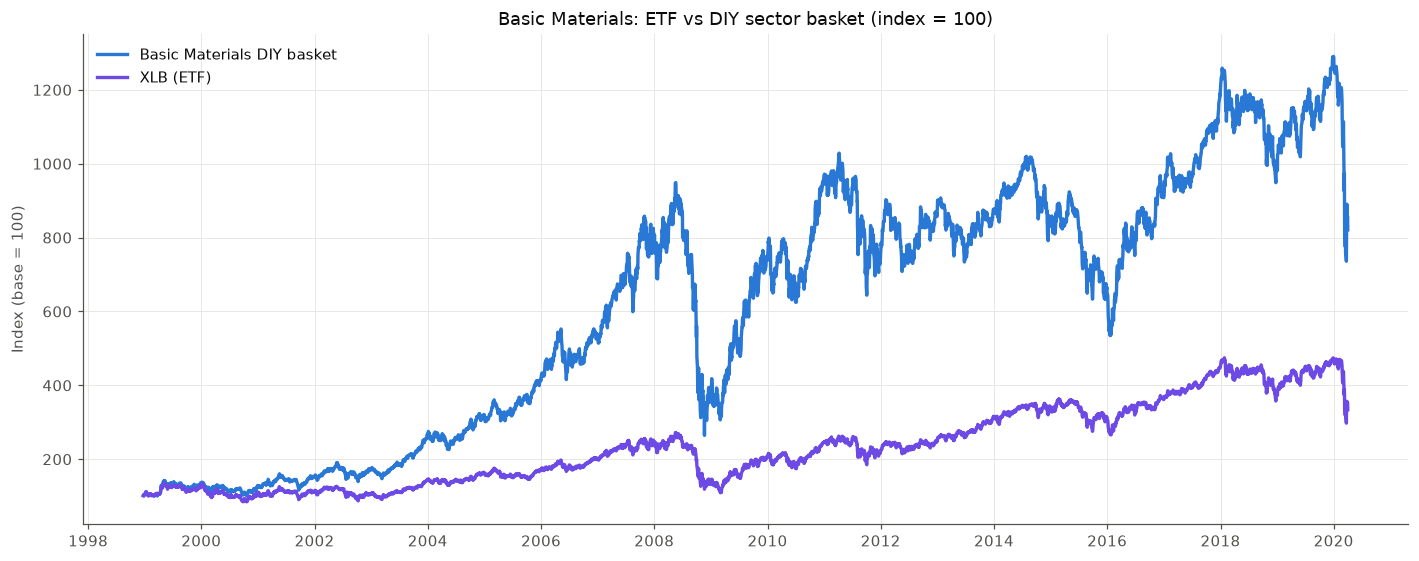

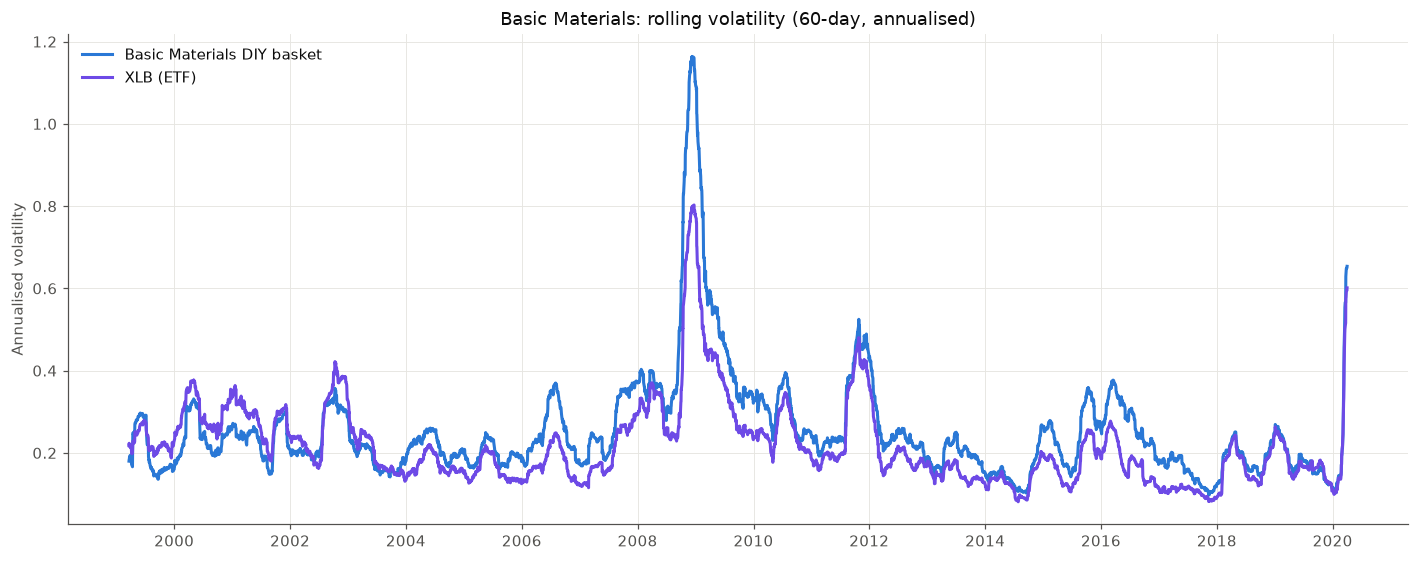

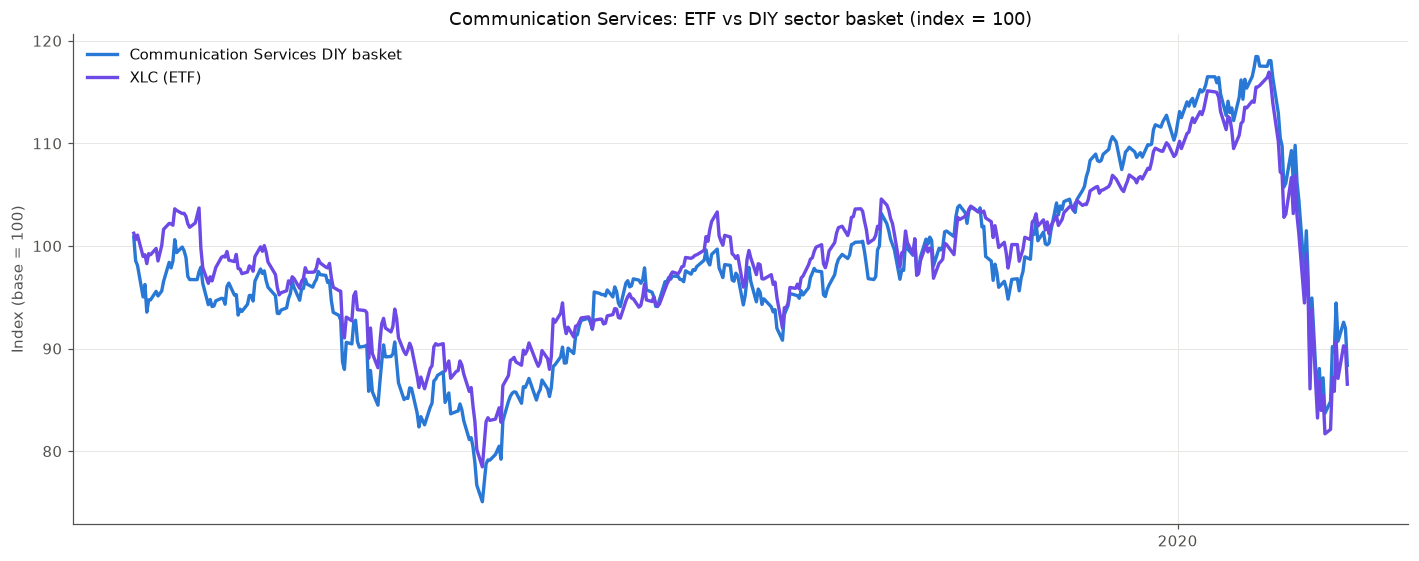

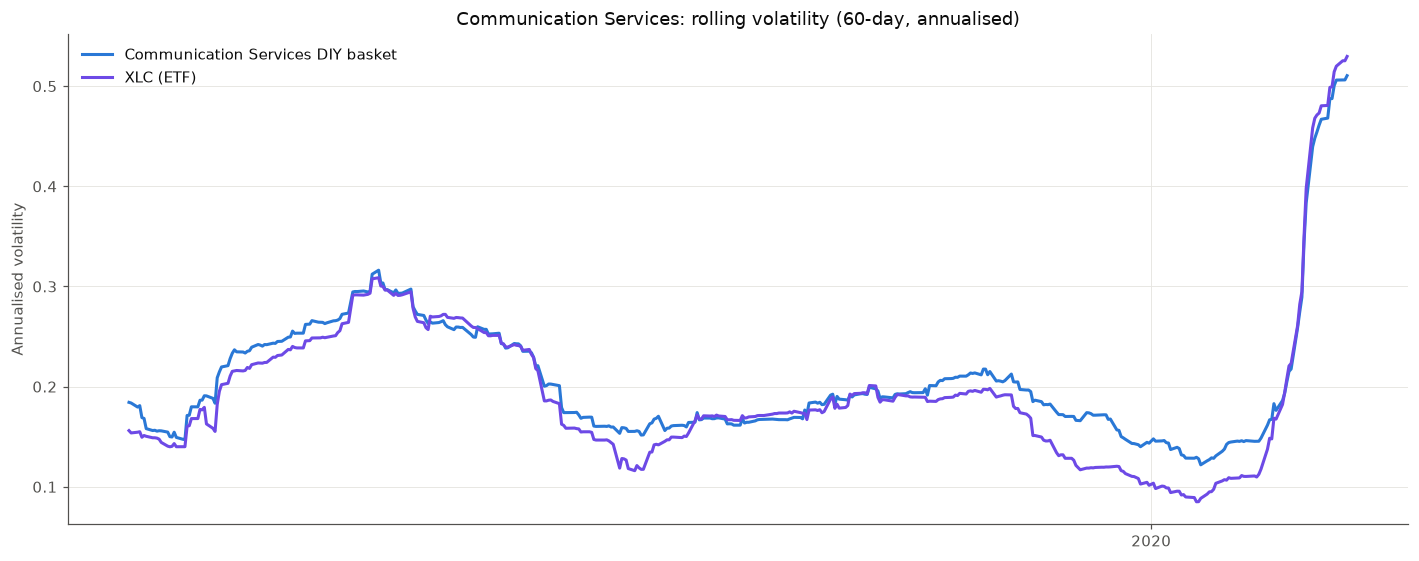

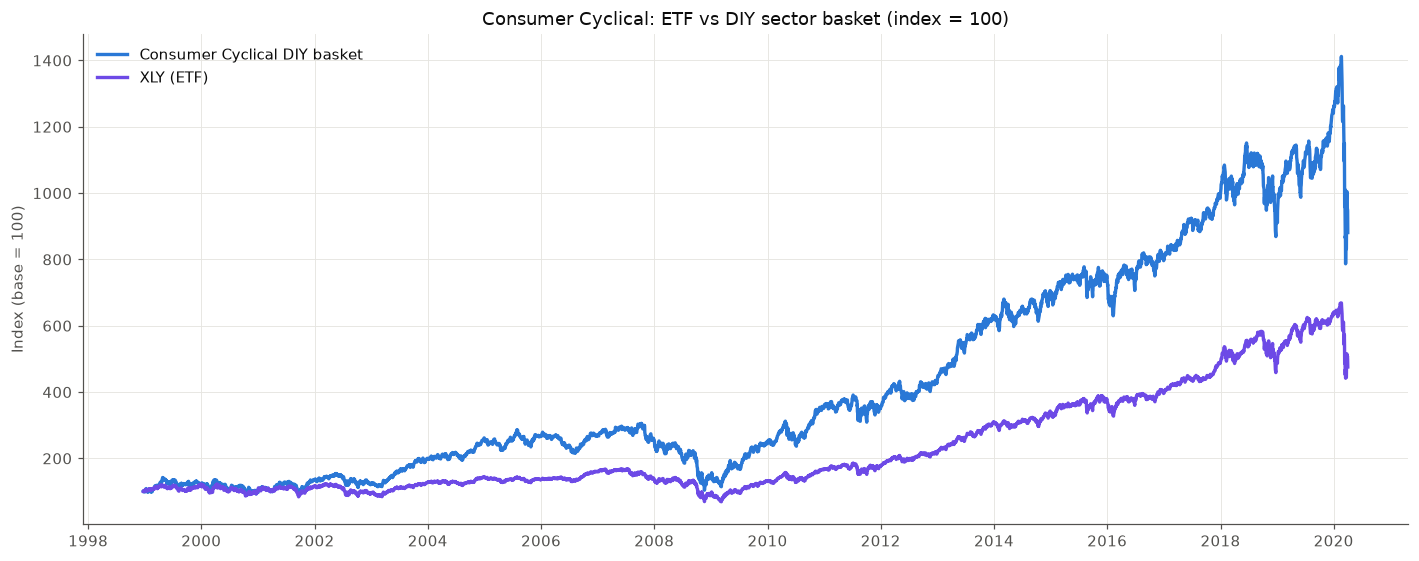

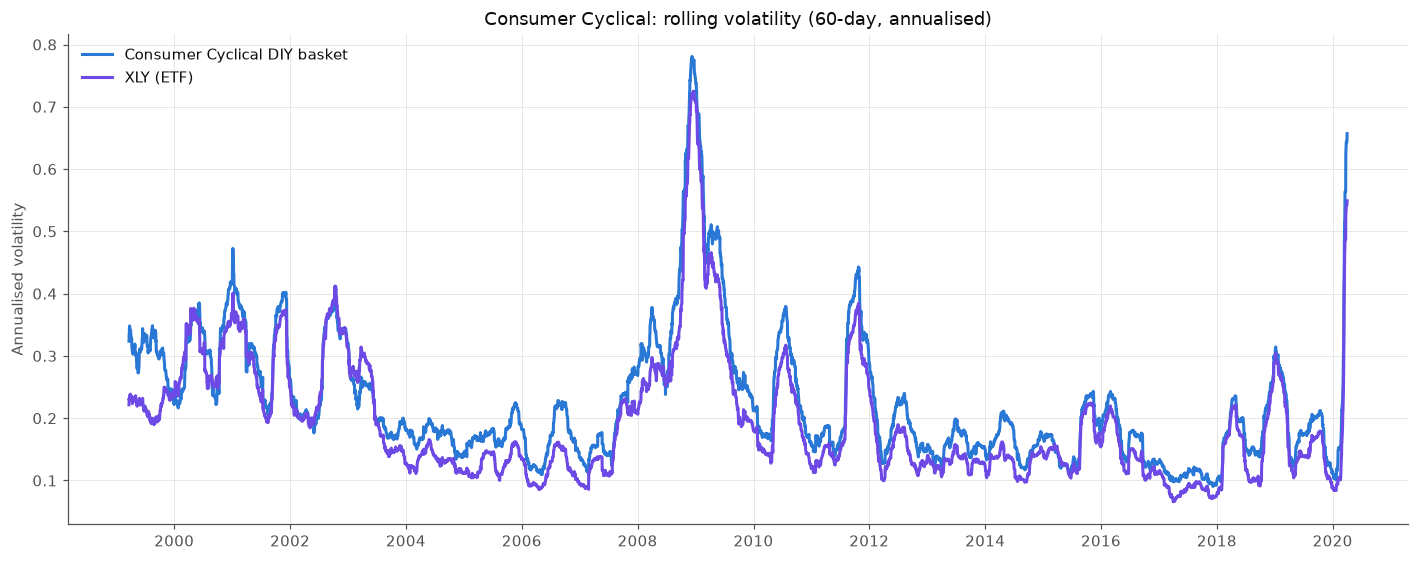

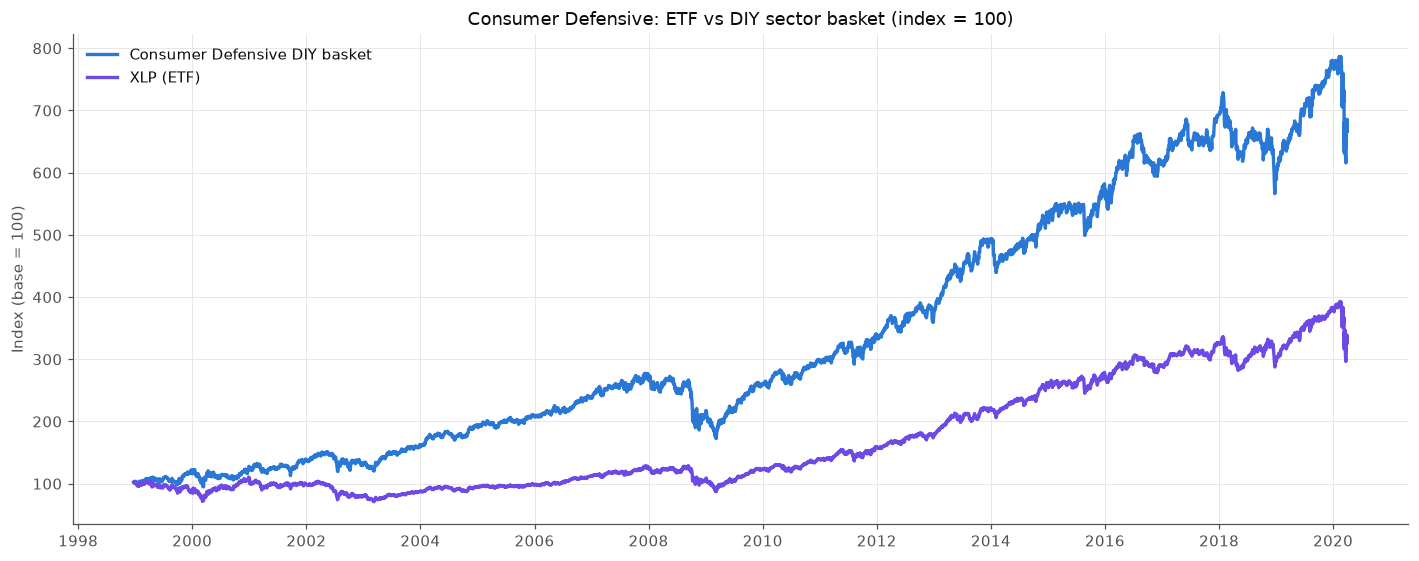

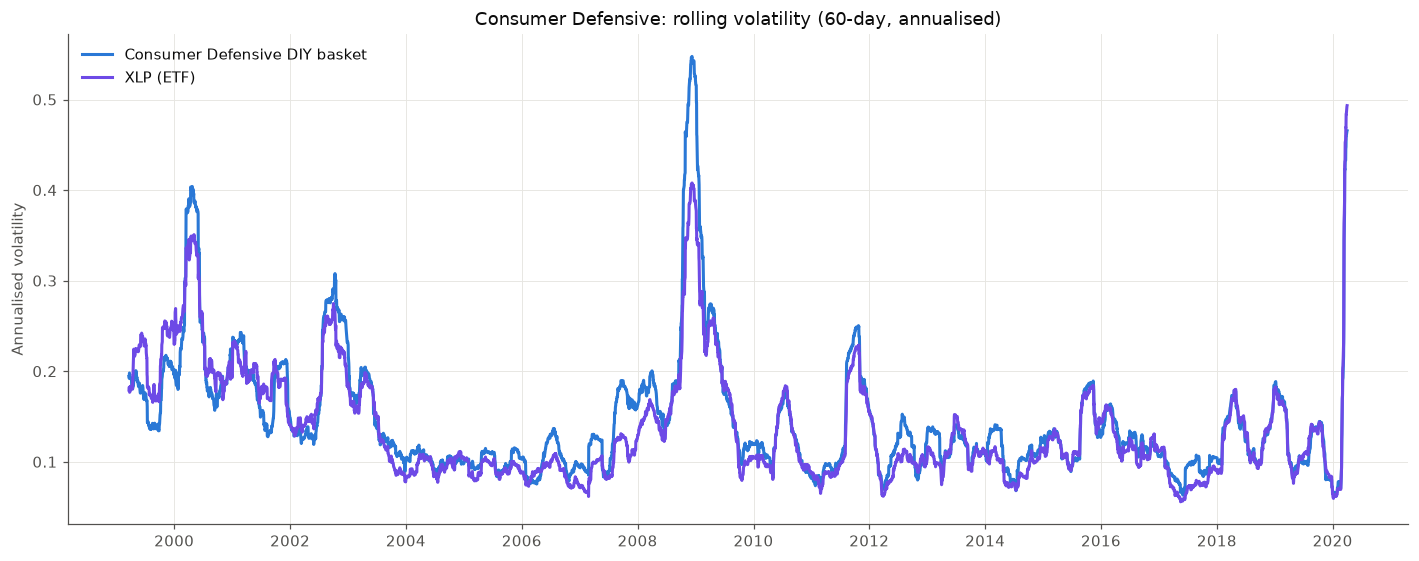

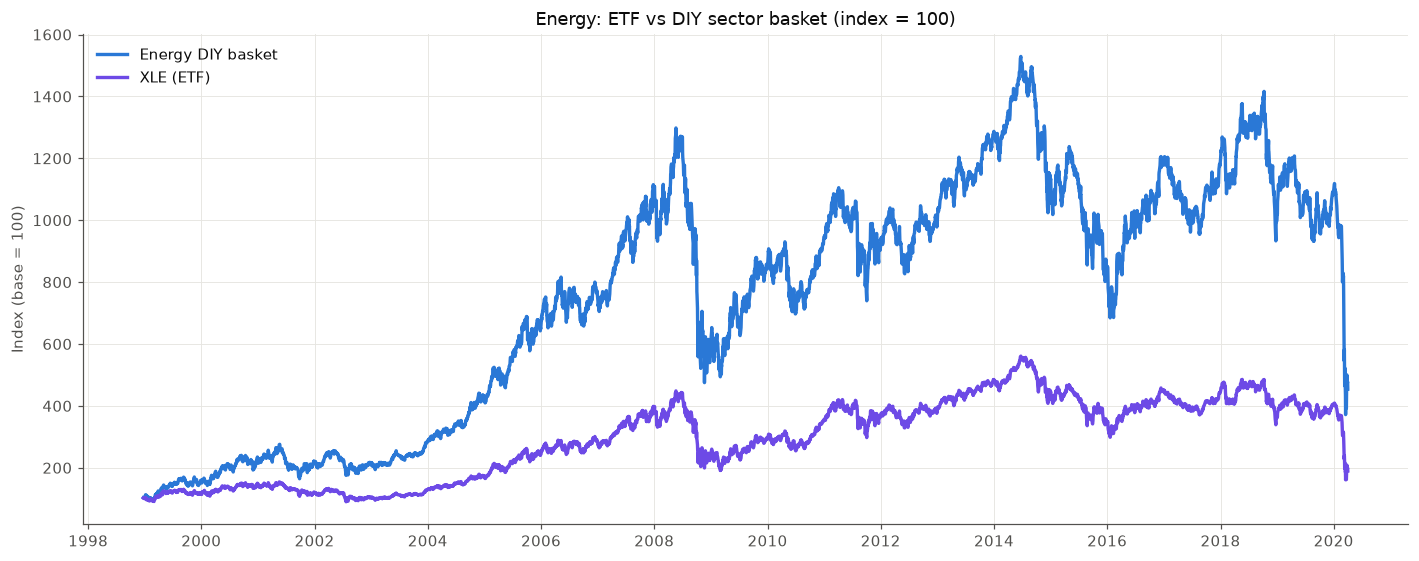

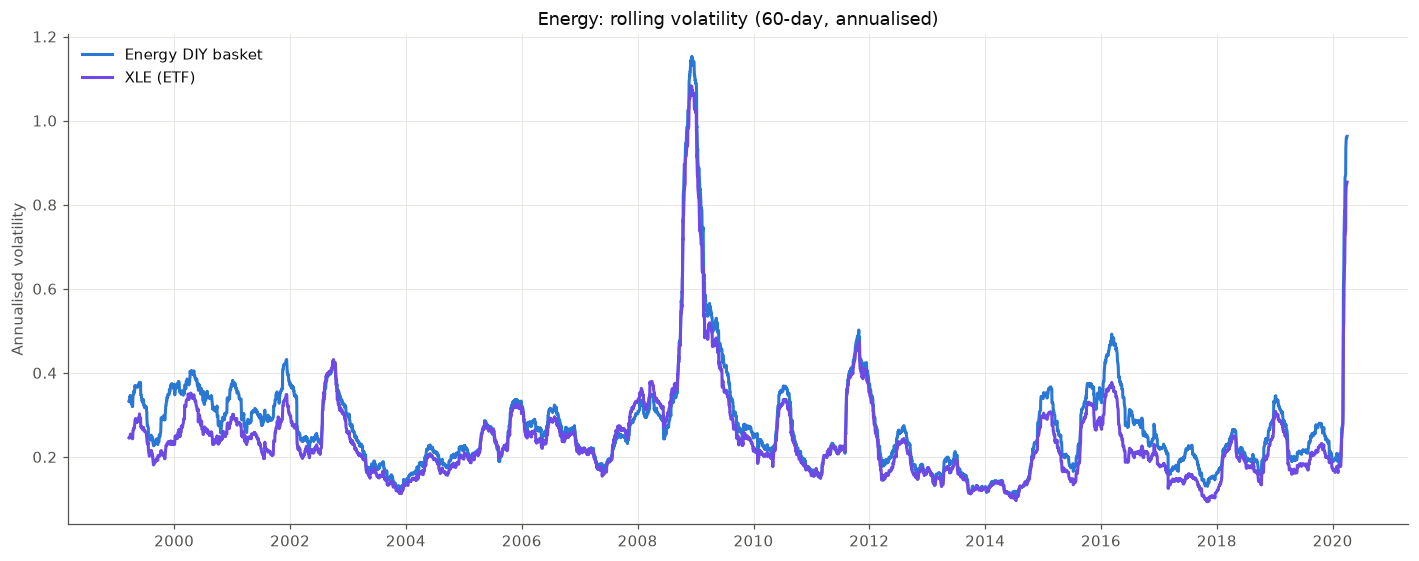

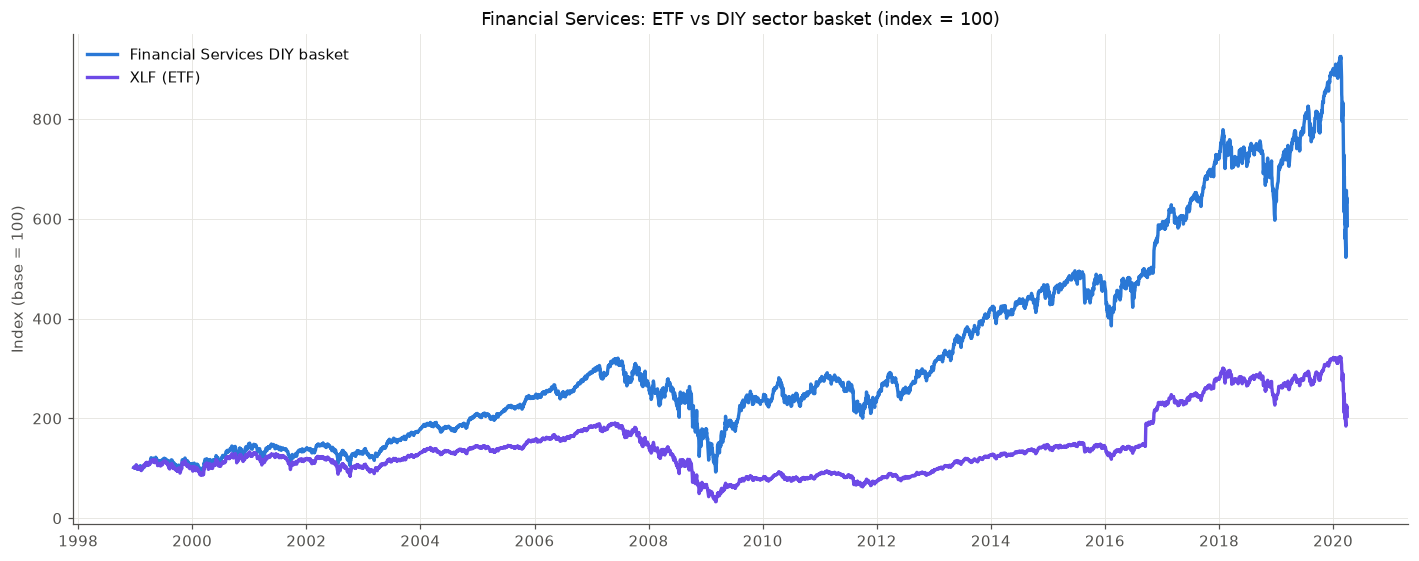

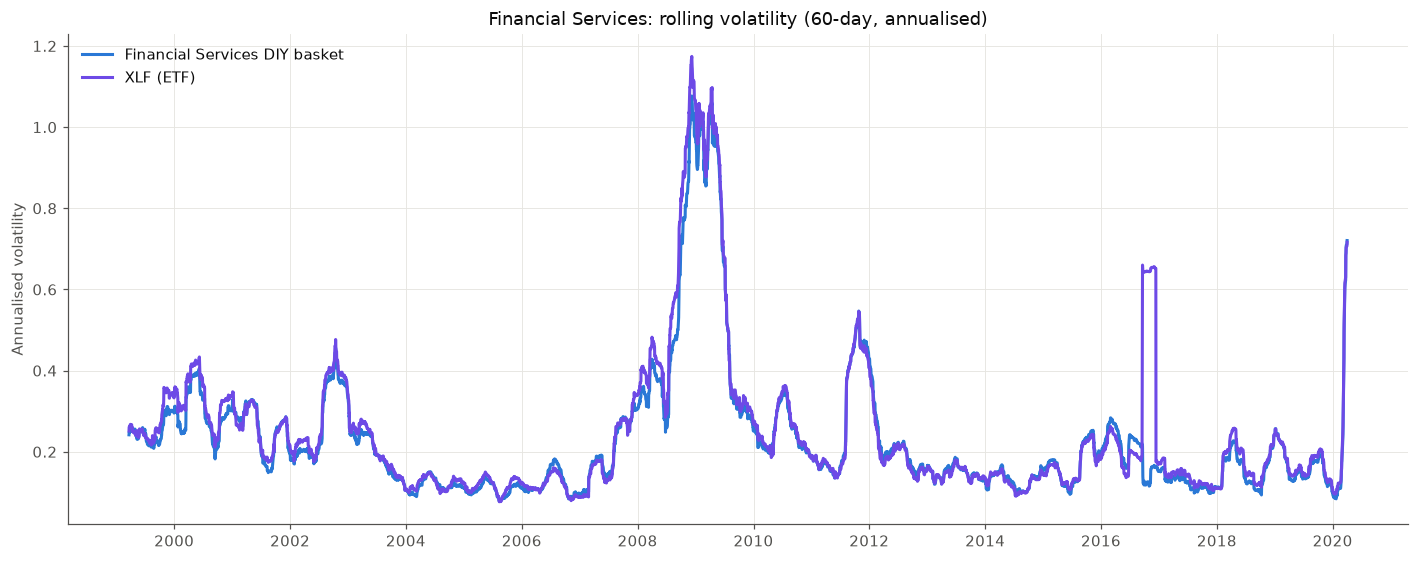

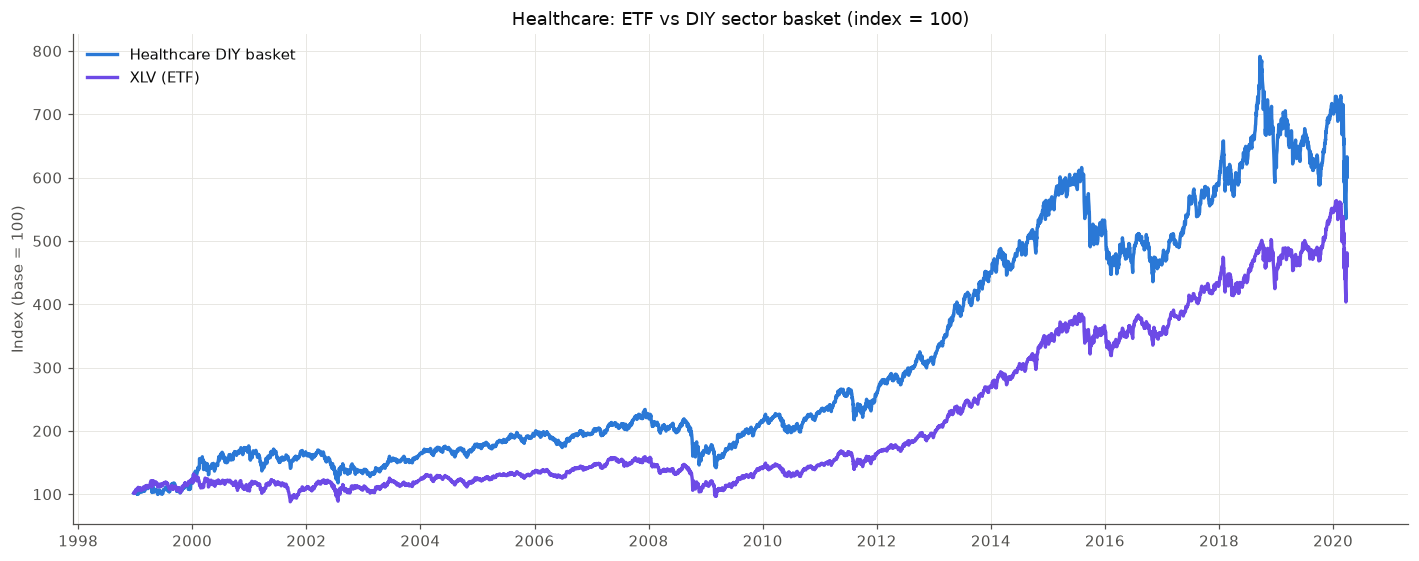

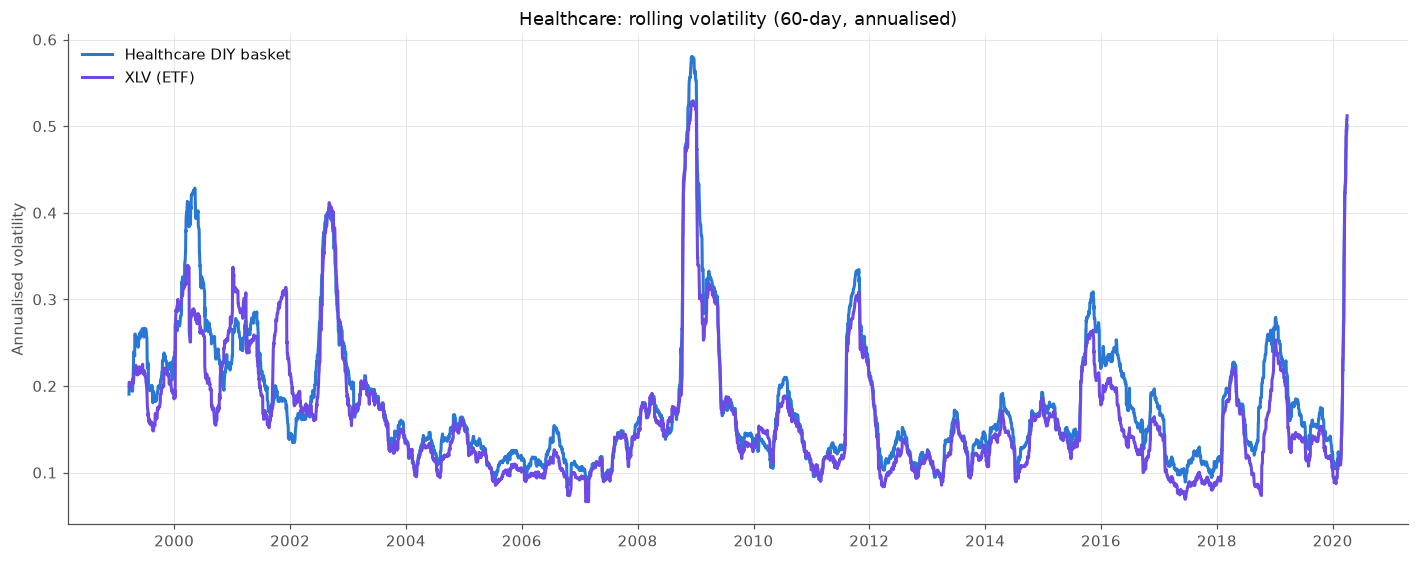

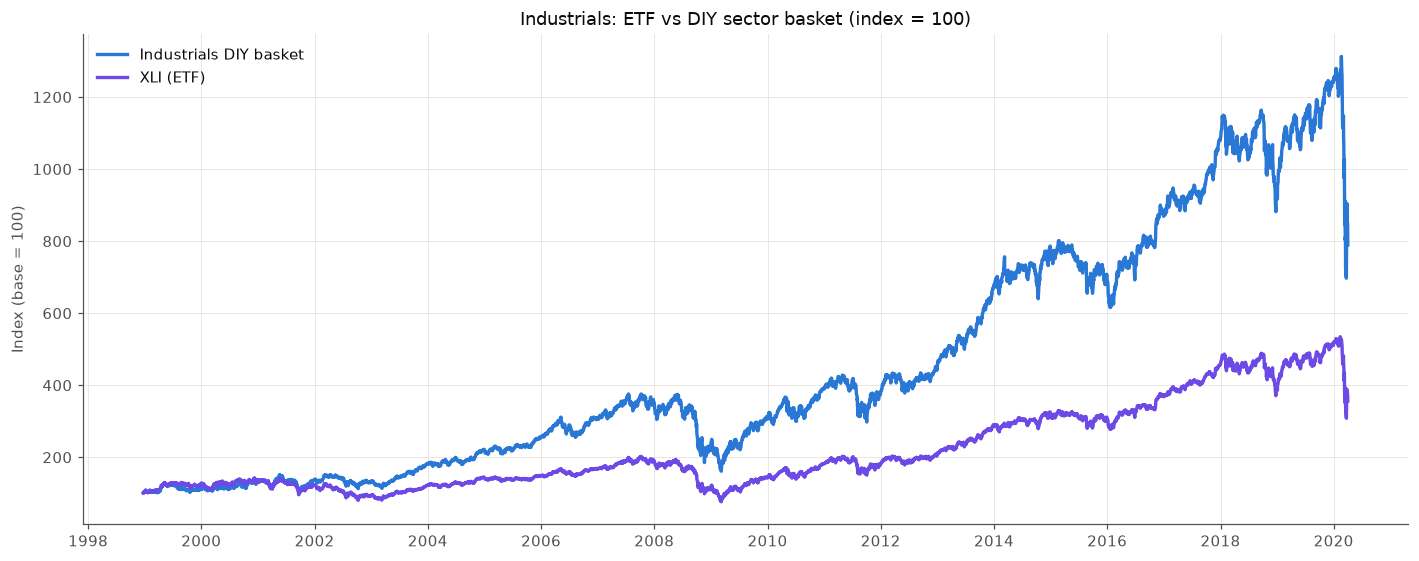

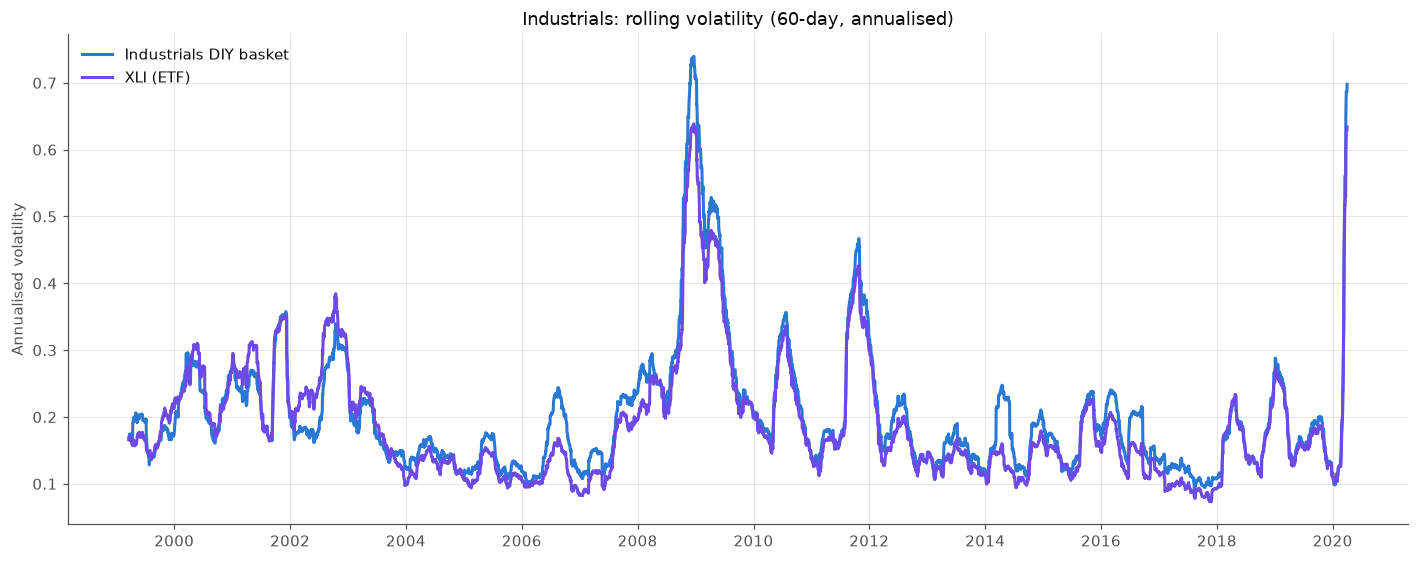

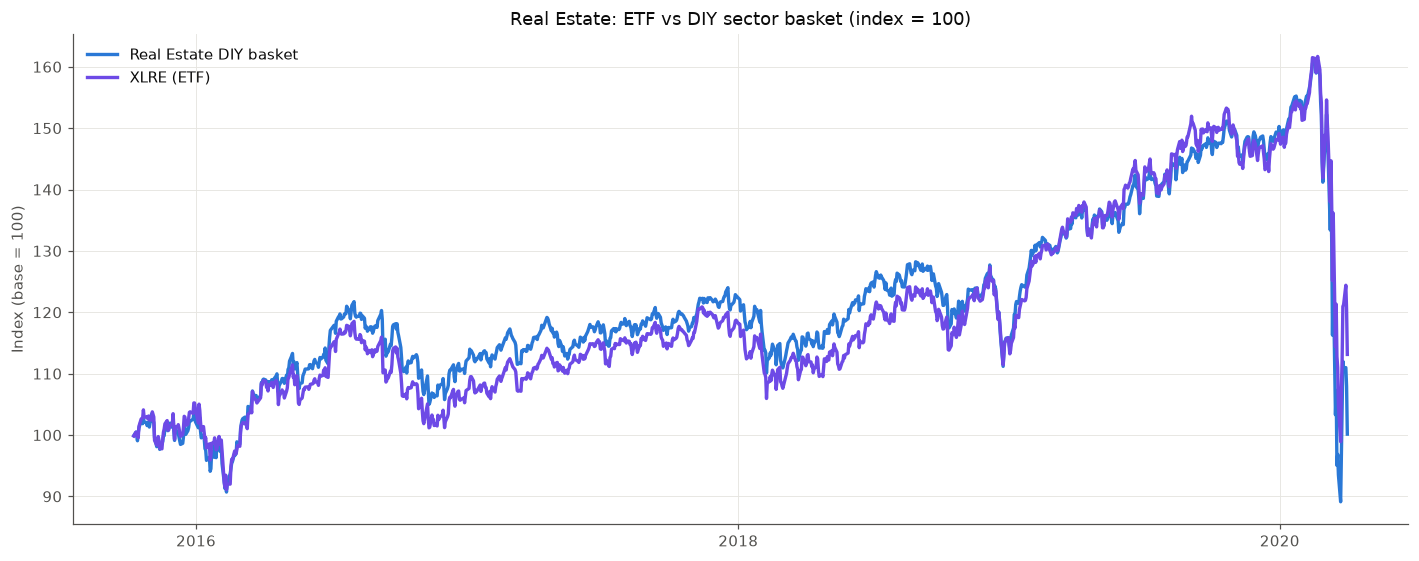

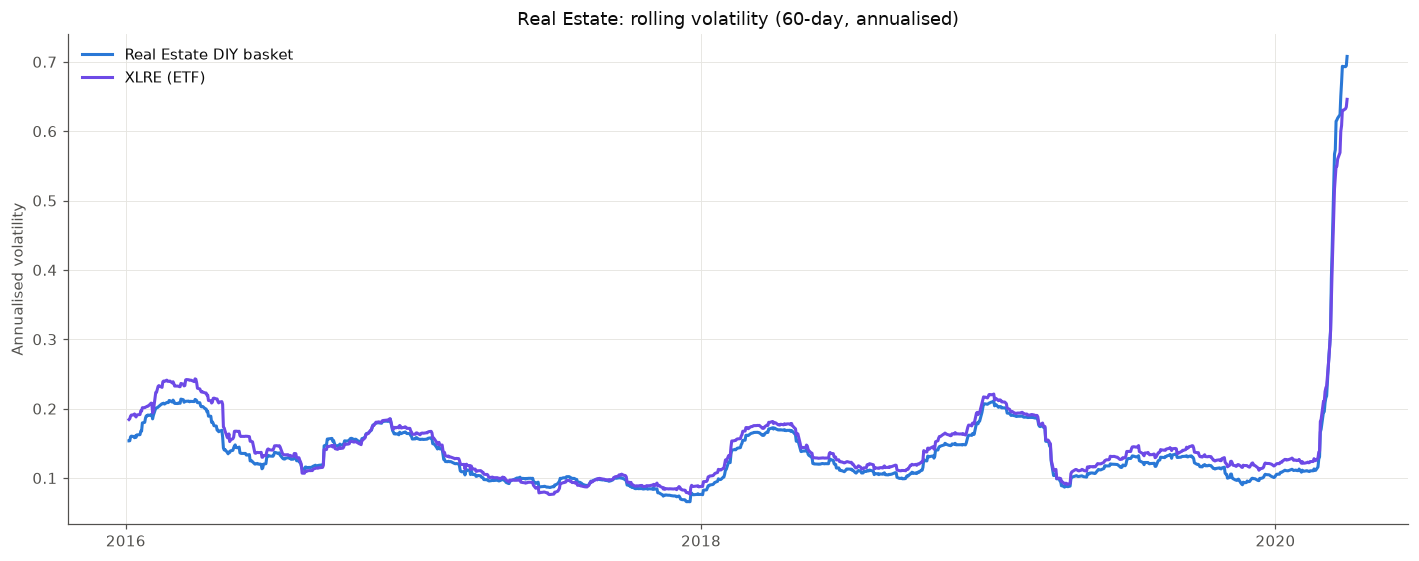

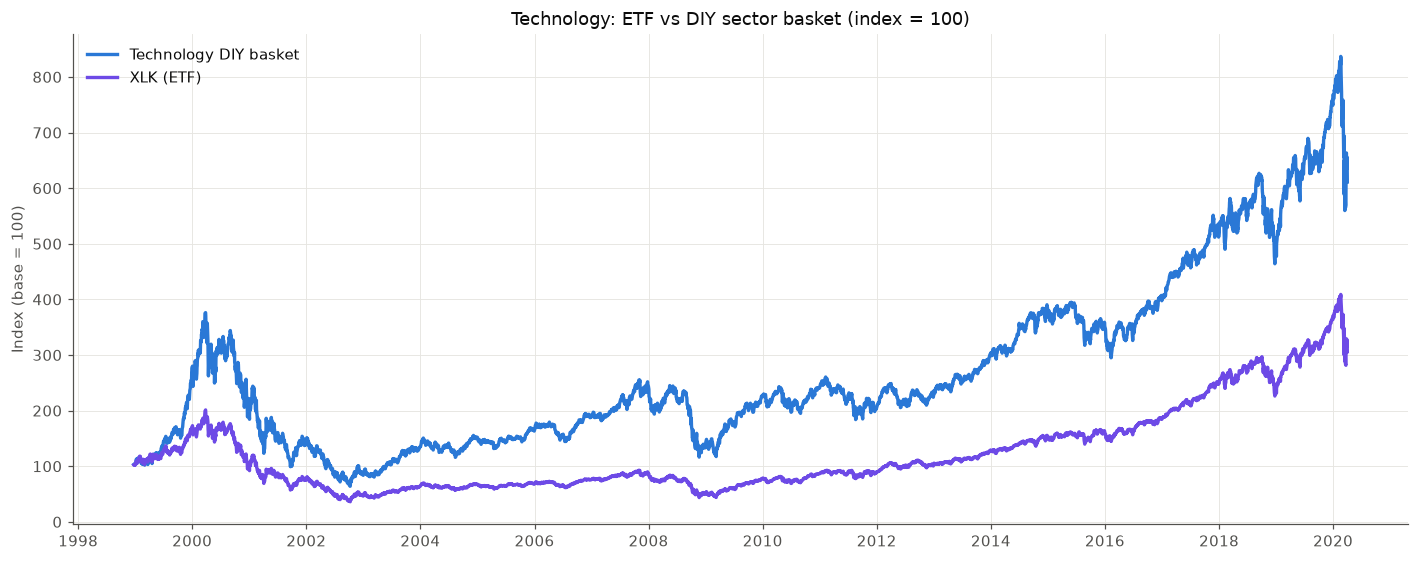

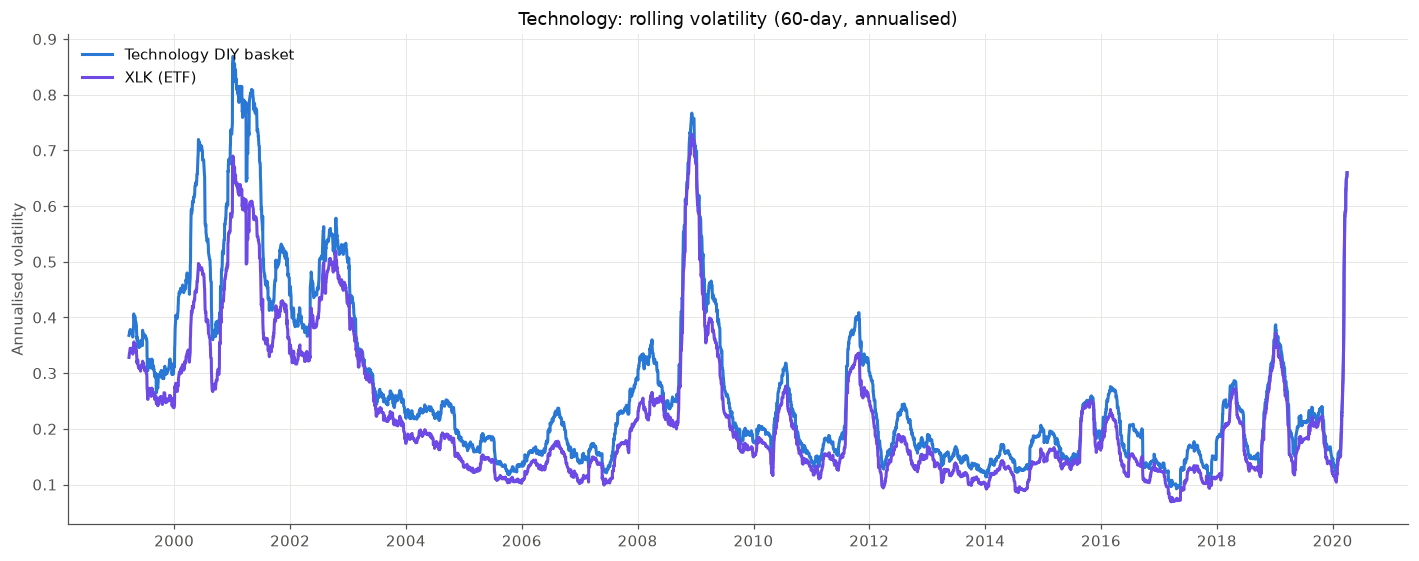

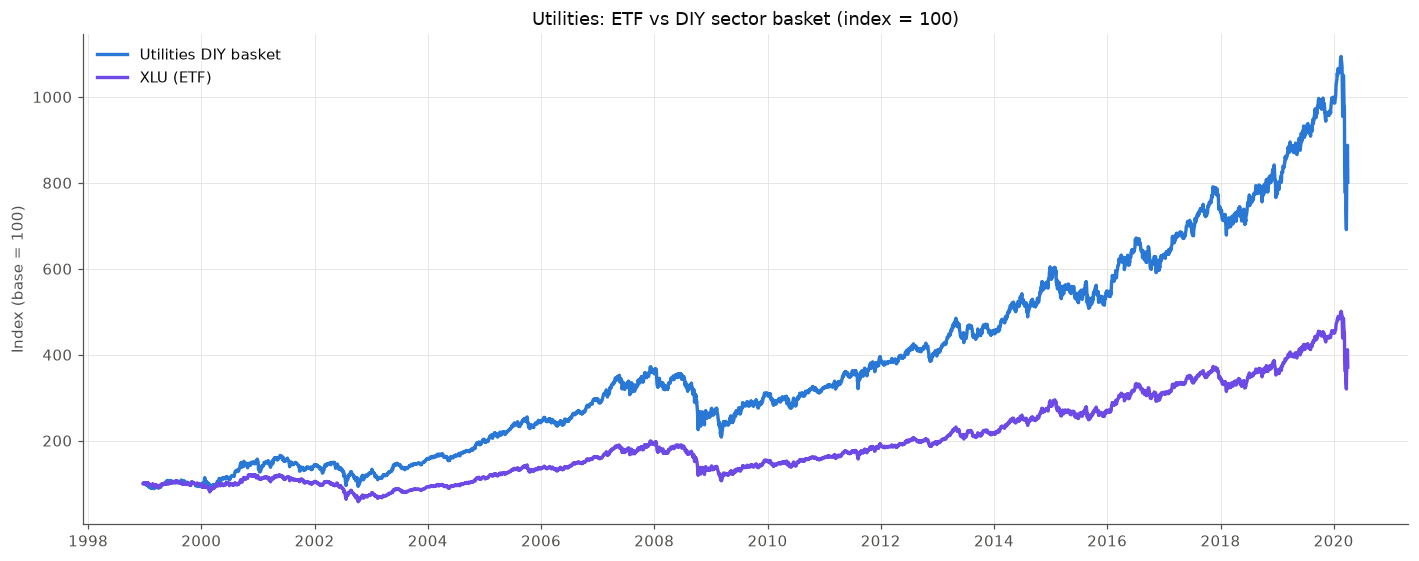

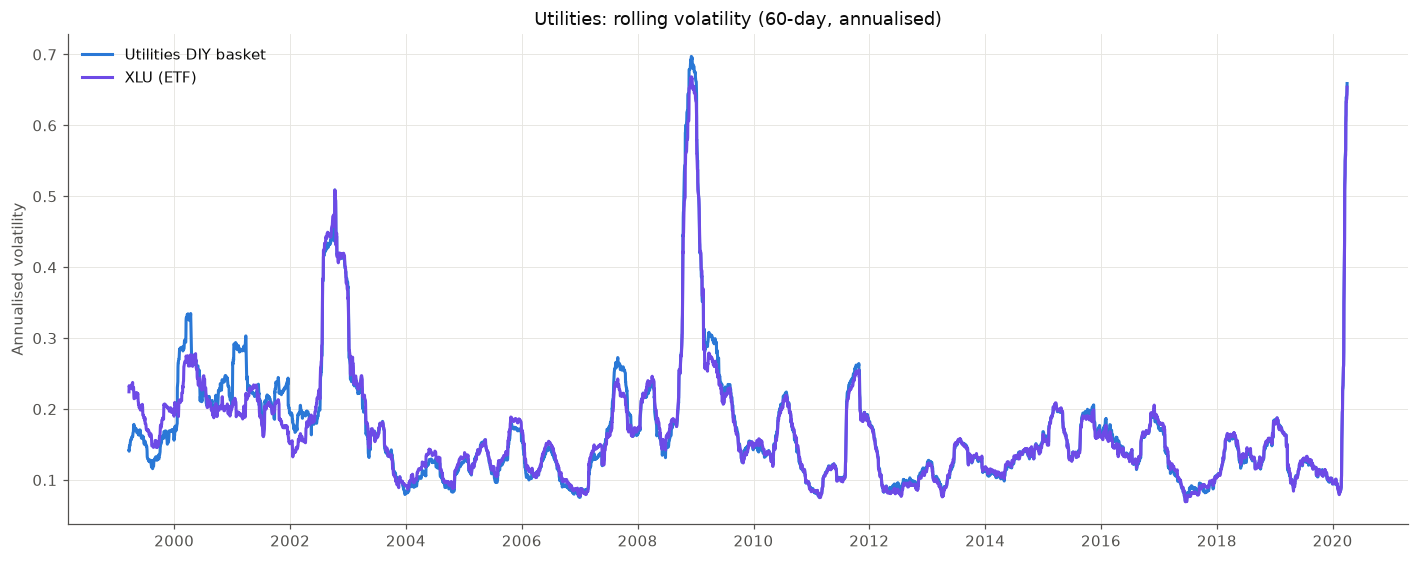

In [3]:
for sector, pair in pairs.items():
    etf = SECTOR_ETFS[sector]
    site_figure(plot_performance, FIG_SECTION, f"performance_{slug(sector)}", pair=pair, sector=sector, etf=etf)
    site_figure(plot_volatility, FIG_SECTION, f"volatility_{slug(sector)}", pair=pair, sector=sector, etf=etf, window=VOL_WINDOW)